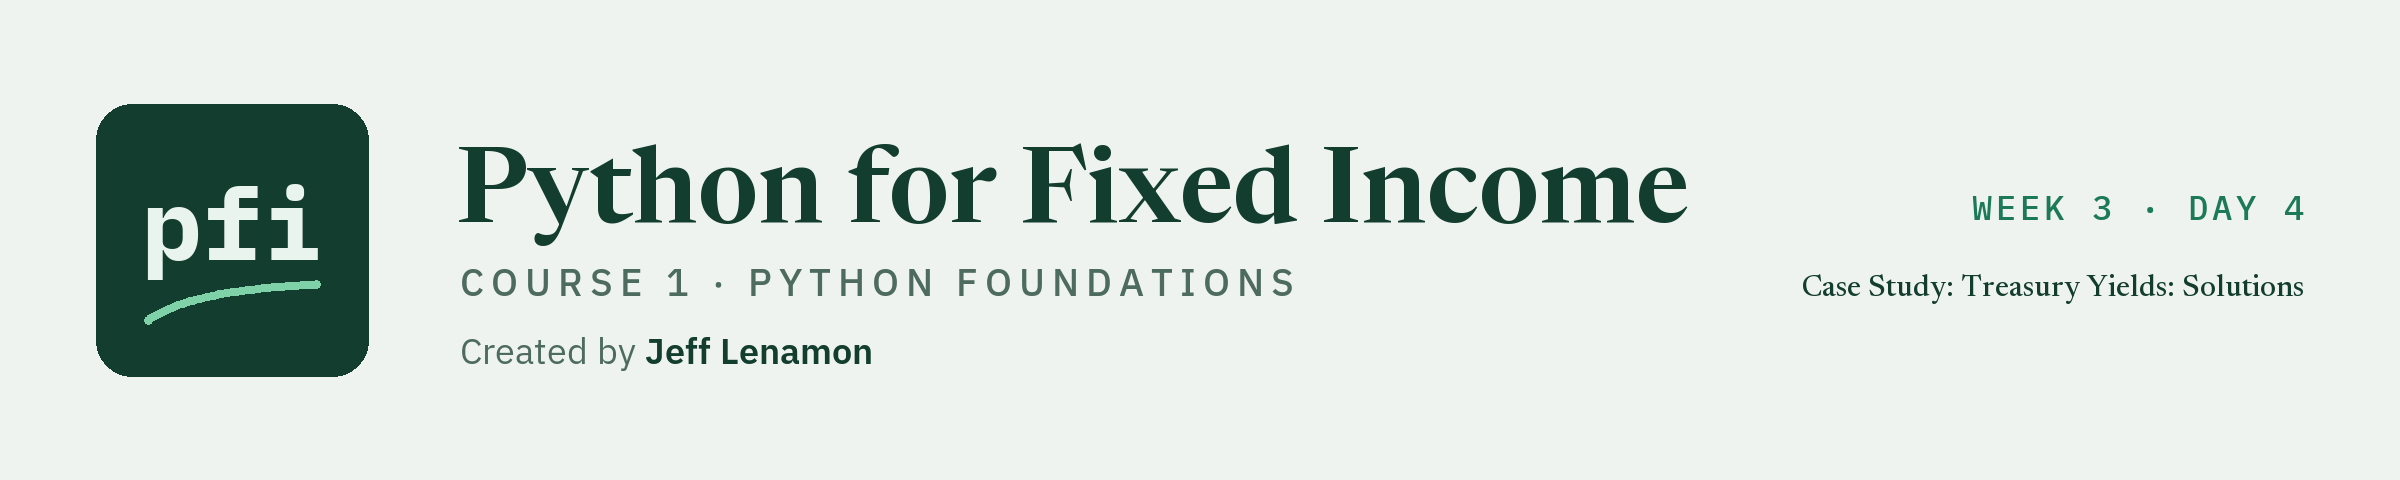

# Case Study: Treasury Yields: Solutions

Week 3, Day 4. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day4/14_case_study_treasury_yields_solutions.ipynb)

## Exercises

These are the worked answers; the yields are Treasury's, as published, retrieved 2026-10-03.
Run the next two cells first: the first defines `check`; the second loads the file.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house theme and a fresh yields, the dates as the row labels
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
if os.path.exists('../../../data/treasury_par_yields.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
yields = pd.read_csv(data_folder + 'treasury_par_yields.csv', parse_dates=['date'],
                     index_col='date')
print(yields.shape)

(2940, 14)


### Exercise 1

Q. Store the `5 Yr` on 2022-06-15 in **ex1_yield**, the rows for 2022 in **ex1_rows**, and the 2022 mean `5 Yr`, to 2 places, in **ex1_mean**.

In [3]:
# a date and a column pick one cell
ex1_yield = yields.loc['2022-06-15', '5 Yr']
# a year alone picks every row of that year
year_2022 = yields.loc['2022']
ex1_rows = len(year_2022)
ex1_mean = round(year_2022['5 Yr'].mean(), 2)
print(ex1_yield, ex1_rows, ex1_mean, '| 2022 low and high:', year_2022['5 Yr'].min(),
      year_2022['5 Yr'].max())

3.38 249 3.0 | 2022 low and high: 1.37 4.45


The `5 Yr` was 3.38 percent on 2022-06-15; 2022 has 249 rows and a mean `5 Yr` of 3.0 percent.
Within 2022 it ran from 1.37 to 4.45 percent.

In [4]:
check('Exercise 1 yield', ex1_yield, 3.38)
check('Exercise 1 rows', ex1_rows, 249)
check('Exercise 1 mean', ex1_mean, 3.0)

Exercise 1 yield: correct
Exercise 1 rows: correct
Exercise 1 mean: correct


### Exercise 2

Q. Find each year's `30 Yr` range in whole basis points. Store the widest year in **ex2_year** and its range in **ex2_range_bp**.

In [5]:
thirty = yields.groupby(yields.index.year)['30 Yr'].agg(['mean', 'min', 'max'])
thirty.index.name = 'year'
# highest less lowest, times 100 for basis points, as whole numbers
thirty['range_bp'] = ((thirty['max'] - thirty['min']) * 100).round().astype(int)
# idxmax() returns the row label: the year
ex2_year = thirty['range_bp'].idxmax()
ex2_range_bp = thirty['range_bp'].max()
thirty.round(2)

,mean,min,max,range_bp
year,,,,
2015,2.84,2.25,3.25,100
2016,2.59,2.11,3.19,108
2017,2.89,2.66,3.20,54
2018,3.11,2.78,3.46,68
2019,2.58,1.94,3.13,119
2020,1.56,0.99,2.38,139
2021,2.06,1.66,2.45,79
2022,3.11,2.01,4.40,239
2023,4.09,3.54,5.11,157


The widest year is 2022, 239 bp, from 2.01 to 4.40 percent; the narrowest 2017, 54.
2026's range is a part year's, to 2 October.
The `10 Yr` in the lesson had its widest and narrowest years in 2022 and 2017 too.

In [6]:
check('Exercise 2 year', ex2_year, 2022)
check('Exercise 2 range', ex2_range_bp, 239)

Exercise 2 year: correct
Exercise 2 range: correct


### Exercise 3

Q. Work out the `10 Yr` less the `3 Mo` in whole basis points. Store the days below zero in **ex3_days** and the year with the most in **ex3_year**. Draw it with a line at zero.

In [7]:
spread = ((yields['10 Yr'] - yields['3 Mo']) * 100).round()
below = spread < 0
ex3_days = below.sum()
below_by_year = below.groupby(yields.index.year).sum()
ex3_year = below_by_year.idxmax()
print(ex3_days, 'days; the most in', ex3_year, below_by_year.max())
print(below_by_year[below_by_year > 0])

738 days; the most in 2023 250
date
2019    104
2020     13
2022     47
2023    250
2024    238
2025     86
dtype: int64


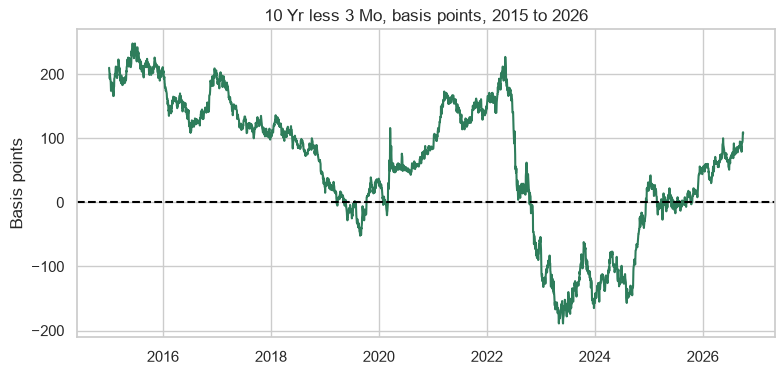

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(spread)
ax.axhline(0, color='black', linestyle='--')
ax.set_title('10 Yr less 3 Mo, basis points, 2015 to 2026')
ax.set_ylabel('Basis points')
plt.show()

738 days below zero, the most in 2023: all 250 of its rows.
The lesson's 10s less 2s was below zero on 544 days: say which two tenors whenever a curve spread is quoted.

In [9]:
check('Exercise 3 days', ex3_days, 738)
check('Exercise 3 year', ex3_year, 2023)

Exercise 3 days: correct
Exercise 3 year: correct


### Exercise 4

Q. Work out the `5 Yr` daily change in basis points. Store the largest rise and fall in **ex4_rise** and **ex4_fall**, and their dates in **ex4_rise_date** and **ex4_fall_date** as text. Draw the histogram.

In [10]:
five = (yields['5 Yr'].diff() * 100).round()
ex4_rise = five.max()
ex4_fall = five.min()
# strftime() writes a date as text in the layout given
ex4_rise_date = five.idxmax().strftime('%Y-%m-%d')
ex4_fall_date = five.idxmin().strftime('%Y-%m-%d')
print(ex4_rise, ex4_rise_date, ex4_fall, ex4_fall_date, '| std', round(five.std(), 2))

31.0 2022-06-13 -32.0 2022-11-10 | std 5.53


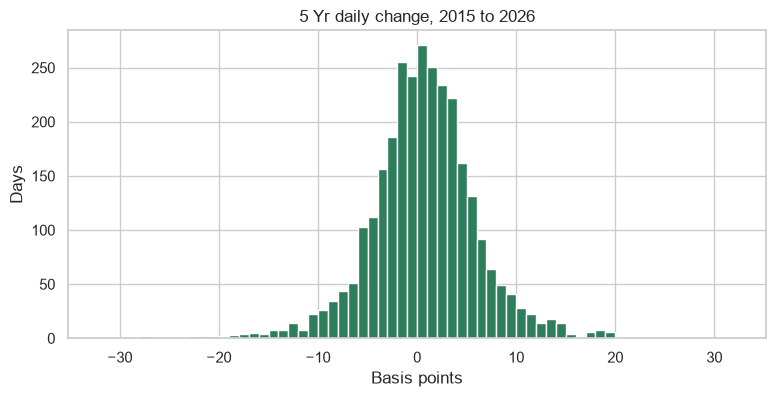

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(five.dropna(), bins=range(-32, 33))
ax.set_title('5 Yr daily change, 2015 to 2026')
ax.set_xlabel('Basis points')
ax.set_ylabel('Days')
plt.show()

The largest rise, 31 bp on 2022-06-13; the largest fall, -32 on 2022-11-10, the date of the `10 Yr`'s largest fall in the lesson.
The `5 Yr` moves a little more than the `10 Yr`: a standard deviation of 5.53 bp against 5.30.

In [12]:
check('Exercise 4 largest rise', ex4_rise, 31.0)
check('Exercise 4 date of the rise', ex4_rise_date, '2022-06-13')
check('Exercise 4 largest fall', ex4_fall, -32.0)
check('Exercise 4 date of the fall', ex4_fall_date, '2022-11-10')

Exercise 4 largest rise: correct
Exercise 4 date of the rise: correct
Exercise 4 largest fall: correct
Exercise 4 date of the fall: correct


### Exercise 5

Q. Complete **curve_spread_bp**: given the table, two tenors, and a date as text, return the first less the second on that date, in whole basis points.

In [13]:
def curve_spread_bp(table, long_tenor, short_tenor, date):
    # one row, picked by its date
    row = table.loc[date]
    # round() clears the float error; int() makes it a whole number
    return int(round((row[long_tenor] - row[short_tenor]) * 100))


ex5_10y_2y = curve_spread_bp(yields, '10 Yr', '2 Yr', '2026-10-02')
ex5_30y_20y = curve_spread_bp(yields, '30 Yr', '20 Yr', '2026-10-02')
ex5_10y_3m = curve_spread_bp(yields, '10 Yr', '3 Mo', '2023-05-04')
print(ex5_10y_2y, ex5_30y_20y, ex5_10y_3m)

45 -4 -189


45 bp on the last date, the lesson's last spread; -4 for the `30 Yr` less the `20 Yr`, 5.63 against 5.67; -189 on 2023-05-04.
The unit is in the name, so nobody reads the result as percent.
A date with no row, such as `'2024-07-04'`, raises a `KeyError`: the right behaviour, since a spread for that date would be invented.

In [14]:
check('Exercise 5 10 Yr less 2 Yr', ex5_10y_2y, 45)
check('Exercise 5 30 Yr less 20 Yr', ex5_30y_20y, -4)
check('Exercise 5 10 Yr less 3 Mo', ex5_10y_3m, -189)

Exercise 5 10 Yr less 2 Yr: correct
Exercise 5 30 Yr less 20 Yr: correct
Exercise 5 10 Yr less 3 Mo: correct


### Exercise 6

Q. Store the `5 Yr` and `30 Yr` correlation, to 2 places, as levels in **ex6_levels** and as whole-bp daily changes in **ex6_changes**. Draw the changes as a scatter.

In [15]:
ex6_levels = round(yields['5 Yr'].corr(yields['30 Yr']), 2)
change_5 = (yields['5 Yr'].diff() * 100).round()
change_30 = (yields['30 Yr'].diff() * 100).round()
ex6_changes = round(change_5.corr(change_30), 2)
print(ex6_levels, ex6_changes)

0.94 0.78


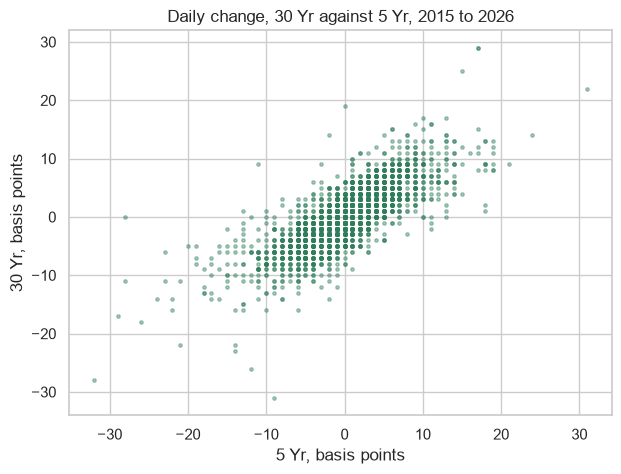

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(change_5, change_30, s=6, alpha=0.4)
ax.set_title('Daily change, 30 Yr against 5 Yr, 2015 to 2026')
ax.set_xlabel('5 Yr, basis points')
ax.set_ylabel('30 Yr, basis points')
plt.show()

0.94 as levels, 0.78 as daily changes: as in the lesson, the levels share the years' trend and the changes leave it out.
The cloud tilts up: the two moved the same way on most days, not by the same amount.

In [17]:
check('Exercise 6 levels', ex6_levels, 0.94)
check('Exercise 6 daily changes', ex6_changes, 0.78)

Exercise 6 levels: correct
Exercise 6 daily changes: correct


### Exercise 7: AI check

Q. How many years should the table have, and what is the 2025 mean? Find the bug and fix the cell.

The lesson's table has 12 years and a 2025 mean of 4.29 percent; the AI's code gave 2 years and 4.25, with no error.
The bug is `data = data.dropna()`: with nothing in the brackets it drops every row with a blank in any column.
`1.5 Month` is blank before 2025-02-18, so 2,532 of the 2,940 rows went, for a column the question never asked about.
The fix: drop the line, since the `10 Yr` has no blank, or name the column with `dropna(subset=['10 Yr'])`.

In [18]:
data = pd.read_csv(data_folder + 'treasury_par_yields.csv', parse_dates=['date'], index_col='date')
# no rows dropped: the 10 Yr has a value on every date
print(len(data), data['10 Yr'].count())
by_year = data.groupby(data.index.year)['10 Yr'].mean().round(2)
ex7_years = len(by_year)
ex7_mean_2025 = by_year.loc[2025]
print('Years:', ex7_years, '| 2025 mean:', ex7_mean_2025, 'percent')

2940 2940
Years: 12 | 2025 mean: 4.29 percent


In [19]:
check('Exercise 7 years', ex7_years, 12)
check('Exercise 7 mean for 2025', ex7_mean_2025, 4.29)

Exercise 7 years: correct
Exercise 7 mean for 2025: correct
